# 09 — Demand Forecasting Feature Engineering V2

## Goal

Improve the current CatBoost demand forecasting model by creating features that describe **historical demand and demand drivers**, while removing `Inventory Level` from the demand model.

### Current benchmark

- Optuna CatBoost Test MAE ≈ **68.89**
- Test RMSE ≈ **87.90**

### Features deliberately excluded

- `Demand Forecast` → potential target leakage / very strong proxy for demand
- `Units Ordered` → future inventory decision rather than pure demand signal
- `Inventory Level` → may be endogenous to previous demand, sales and replenishment

### Main feature groups

1. Historical demand lags
2. Rolling demand statistics
3. Demand trend / momentum
4. Calendar features
5. Price and competitor-price features
6. Promotion / discount features
7. Native categorical features

We will compare this feature set against the existing model to determine whether removing inventory improves generalization.

In [1]:
import pandas as pd
import numpy as np
import warnings
import joblib

from pathlib import Path
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from catboost import CatBoostRegressor

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", None)

print("Libraries imported successfully!")

Libraries imported successfully!


## 1. Load and sort the raw dataset

In [2]:
df = pd.read_csv("../DATA/retail_store_inventory.csv")

df["Date"] = pd.to_datetime(df["Date"])

df = df.sort_values(
    ["Store ID", "Product ID", "Date"]
).reset_index(drop=True)

group_cols = ["Store ID", "Product ID"]

print("Shape:", df.shape)
print("Date:", df["Date"].min(), "→", df["Date"].max())

Shape: (73100, 15)
Date: 2022-01-01 00:00:00 → 2024-01-01 00:00:00


## 2. Calendar features

In [3]:
df["Year"] = df["Date"].dt.year
df["Month"] = df["Date"].dt.month
df["Day"] = df["Date"].dt.day
df["Day_of_Week"] = df["Date"].dt.dayofweek
df["Week_of_Year"] = df["Date"].dt.isocalendar().week.astype(int)
df["Quarter"] = df["Date"].dt.quarter
df["Is_Weekend"] = (df["Day_of_Week"] >= 5).astype(int)

print(df[
    ["Date", "Year", "Month", "Day_of_Week",
     "Week_of_Year", "Quarter", "Is_Weekend"]
].head())

        Date  Year  Month  Day_of_Week  Week_of_Year  Quarter  Is_Weekend
0 2022-01-01  2022      1            5            52        1           1
1 2022-01-02  2022      1            6            52        1           1
2 2022-01-03  2022      1            0             1        1           0
3 2022-01-04  2022      1            1             1        1           0
4 2022-01-05  2022      1            2             1        1           0


## 3. Historical demand lag features

All lag values use only information available **before the current date**.

In [4]:
lag_periods = [1, 2, 3, 7, 14, 21, 28]

for lag in lag_periods:
    df[f"Lag_{lag}"] = (
        df.groupby(group_cols)["Units Sold"].shift(lag)
    )

print(df[
    ["Date", "Store ID", "Product ID", "Units Sold"] +
    [f"Lag_{lag}" for lag in lag_periods]
].head(35))

         Date Store ID Product ID  Units Sold  Lag_1  Lag_2  Lag_3  Lag_7  \
0  2022-01-01     S001      P0001         127    NaN    NaN    NaN    NaN   
1  2022-01-02     S001      P0001          81  127.0    NaN    NaN    NaN   
2  2022-01-03     S001      P0001           5   81.0  127.0    NaN    NaN   
3  2022-01-04     S001      P0001          58    5.0   81.0  127.0    NaN   
4  2022-01-05     S001      P0001         147   58.0    5.0   81.0    NaN   
5  2022-01-06     S001      P0001          37  147.0   58.0    5.0    NaN   
6  2022-01-07     S001      P0001         107   37.0  147.0   58.0    NaN   
7  2022-01-08     S001      P0001           2  107.0   37.0  147.0  127.0   
8  2022-01-09     S001      P0001         350    2.0  107.0   37.0   81.0   
9  2022-01-10     S001      P0001          36  350.0    2.0  107.0    5.0   
10 2022-01-11     S001      P0001          16   36.0  350.0    2.0   58.0   
11 2022-01-12     S001      P0001         104   16.0   36.0  350.0  147.0   

## 4. Rolling demand statistics

We shift by one day before calculating rolling statistics so the current target is never included.

In [5]:
demand_group = df.groupby(group_cols)["Units Sold"]

df["Rolling_Mean_7"] = demand_group.transform(
    lambda x: x.shift(1).rolling(7).mean()
)

df["Rolling_Mean_14"] = demand_group.transform(
    lambda x: x.shift(1).rolling(14).mean()
)

df["Rolling_Mean_28"] = demand_group.transform(
    lambda x: x.shift(1).rolling(28).mean()
)

df["Rolling_Std_7"] = demand_group.transform(
    lambda x: x.shift(1).rolling(7).std()
)

df["Rolling_Std_28"] = demand_group.transform(
    lambda x: x.shift(1).rolling(28).std()
)

df["Rolling_Min_7"] = demand_group.transform(
    lambda x: x.shift(1).rolling(7).min()
)

df["Rolling_Max_7"] = demand_group.transform(
    lambda x: x.shift(1).rolling(7).max()
)

print(df[
    ["Date", "Units Sold",
     "Rolling_Mean_7", "Rolling_Mean_14",
     "Rolling_Mean_28", "Rolling_Std_7",
     "Rolling_Std_28", "Rolling_Min_7",
     "Rolling_Max_7"]
].head(35))

         Date  Units Sold  Rolling_Mean_7  Rolling_Mean_14  Rolling_Mean_28  \
0  2022-01-01         127             NaN              NaN              NaN   
1  2022-01-02          81             NaN              NaN              NaN   
2  2022-01-03           5             NaN              NaN              NaN   
3  2022-01-04          58             NaN              NaN              NaN   
4  2022-01-05         147             NaN              NaN              NaN   
5  2022-01-06          37             NaN              NaN              NaN   
6  2022-01-07         107             NaN              NaN              NaN   
7  2022-01-08           2       80.285714              NaN              NaN   
8  2022-01-09         350       62.428571              NaN              NaN   
9  2022-01-10          36      100.857143              NaN              NaN   
10 2022-01-11          16      105.285714              NaN              NaN   
11 2022-01-12         104       99.285714           

## 5. Demand trend and momentum features

In [6]:
# Recent demand compared with longer-term demand
df["Demand_Momentum_7_28"] = (
    df["Rolling_Mean_7"] /
    df["Rolling_Mean_28"].replace(0, np.nan)
)

# Difference between short and long-term demand
df["Demand_Trend_7_28"] = (
    df["Rolling_Mean_7"] -
    df["Rolling_Mean_28"]
)

# Recent volatility relative to mean
df["Demand_CV_7"] = (
    df["Rolling_Std_7"] /
    df["Rolling_Mean_7"].replace(0, np.nan)
)

# Day-to-day demand change
df["Demand_Change_1"] = (
    df.groupby(group_cols)["Units Sold"].diff(1)
)

print(df[
    ["Date", "Units Sold",
     "Demand_Momentum_7_28",
     "Demand_Trend_7_28",
     "Demand_CV_7",
     "Demand_Change_1"]
].tail())

            Date  Units Sold  Demand_Momentum_7_28  Demand_Trend_7_28  \
73095 2023-12-28          56              0.888256         -16.821429   
73096 2023-12-29         268              0.821323         -25.857143   
73097 2023-12-30         149              0.836651         -24.321429   
73098 2023-12-31          40              0.772420         -33.714286   
73099 2024-01-01           6              0.810483         -27.892857   

       Demand_CV_7  Demand_Change_1  
73095     0.642448            -82.0  
73096     0.753156            212.0  
73097     0.790509           -119.0  
73098     0.789374           -109.0  
73099     0.706147            -34.0  


## 6. Price and competitive-price features

In [7]:
df["Price_Difference"] = (
    df["Price"] - df["Competitor Pricing"]
)

df["Price_Ratio"] = (
    df["Price"] /
    df["Competitor Pricing"].replace(0, np.nan)
)

df["Relative_Price_Premium"] = (
    (df["Price"] - df["Competitor Pricing"]) /
    df["Competitor Pricing"].replace(0, np.nan)
)

# Price after discount
df["Effective_Price"] = (
    df["Price"] * (1 - df["Discount"] / 100)
)

# Interaction between promotion and discount
df["Promotion_Discount"] = (
    df["Holiday/Promotion"] * df["Discount"]
)

print(df[
    ["Price", "Competitor Pricing",
     "Price_Difference", "Price_Ratio",
     "Relative_Price_Premium",
     "Discount", "Effective_Price",
     "Holiday/Promotion", "Promotion_Discount"]
].head())

   Price  Competitor Pricing  Price_Difference  Price_Ratio  \
0  33.50               29.69              3.81     1.128326   
1  27.95               30.89             -2.94     0.904824   
2  62.70               58.22              4.48     1.076950   
3  77.88               75.99              1.89     1.024872   
4  28.46               29.40             -0.94     0.968027   

   Relative_Price_Premium  Discount  Effective_Price  Holiday/Promotion  \
0                0.128326        20           26.800                  0   
1               -0.095176        10           25.155                  0   
2                0.076950        20           50.160                  0   
3                0.024872        15           66.198                  1   
4               -0.031973        20           22.768                  1   

   Promotion_Discount  
0                   0  
1                   0  
2                   0  
3                  15  
4                  20  


## 7. Define the final demand feature set

Notice that `Inventory Level`, `Units Ordered`, and `Demand Forecast` are intentionally absent.

In [8]:
categorical_features = [
    "Store ID",
    "Product ID",
    "Category",
    "Region",
    "Weather Condition",
    "Seasonality"
]

numerical_features = [
    "Price",
    "Discount",
    "Holiday/Promotion",
    "Competitor Pricing",

    "Year",
    "Month",
    "Day",
    "Day_of_Week",
    "Week_of_Year",
    "Quarter",
    "Is_Weekend",

    "Lag_1",
    "Lag_2",
    "Lag_3",
    "Lag_7",
    "Lag_14",
    "Lag_21",
    "Lag_28",

    "Rolling_Mean_7",
    "Rolling_Mean_14",
    "Rolling_Mean_28",
    "Rolling_Std_7",
    "Rolling_Std_28",
    "Rolling_Min_7",
    "Rolling_Max_7",

    "Demand_Momentum_7_28",
    "Demand_Trend_7_28",
    "Demand_CV_7",
    "Demand_Change_1",

    "Price_Difference",
    "Price_Ratio",
    "Relative_Price_Premium",
    "Effective_Price",
    "Promotion_Discount"
]

feature_columns = categorical_features + numerical_features

excluded_columns = [
    "Inventory Level",
    "Units Ordered",
    "Demand Forecast"
]

print("Number of features:", len(feature_columns))
print("\nExcluded:", excluded_columns)

for col in excluded_columns:
    assert col not in feature_columns

print("\nFeature leakage/exclusion check passed!")

Number of features: 40

Excluded: ['Inventory Level', 'Units Ordered', 'Demand Forecast']

Feature leakage/exclusion check passed!


## 8. Remove rows without enough history

In [9]:
required_history = [
    "Lag_28",
    "Rolling_Mean_28",
    "Rolling_Std_28",
    "Rolling_Min_7",
    "Rolling_Max_7"
]

df_model = df.dropna(
    subset=required_history
).copy()

# Replace possible infinite values created by ratios.
df_model = df_model.replace(
    [np.inf, -np.inf],
    np.nan
)

df_model = df_model.dropna(
    subset=feature_columns
).copy()

print("Model shape:", df_model.shape)
print("Date:", df_model["Date"].min(), "→", df_model["Date"].max())

Model shape: (70300, 45)
Date: 2022-01-29 00:00:00 → 2024-01-01 00:00:00


## 9. Build X and y

In [10]:
X = df_model[feature_columns].copy()
y = df_model["Units Sold"].copy()

for col in categorical_features:
    X[col] = X[col].astype(str)

print("X shape:", X.shape)
print("y shape:", y.shape)
print("\nTarget statistics:")
print(y.describe())

X shape: (70300, 40)
y shape: (70300,)

Target statistics:
count    70300.000000
mean       136.500626
std        109.018835
min          0.000000
25%         48.000000
50%        107.000000
75%        203.000000
max        499.000000
Name: Units Sold, dtype: float64


## 10. Chronological train / validation / test split

In [11]:
unique_dates = np.sort(df_model["Date"].unique())

n_dates = len(unique_dates)

train_end_idx = int(n_dates * 0.70)
validation_end_idx = int(n_dates * 0.85)

train_end_date = unique_dates[train_end_idx - 1]
validation_end_date = unique_dates[validation_end_idx - 1]

train_mask = df_model["Date"] <= train_end_date
val_mask = (
    (df_model["Date"] > train_end_date) &
    (df_model["Date"] <= validation_end_date)
)
test_mask = df_model["Date"] > validation_end_date

X_train = X.loc[train_mask].copy()
y_train = y.loc[train_mask].copy()

X_val = X.loc[val_mask].copy()
y_val = y.loc[val_mask].copy()

X_test = X.loc[test_mask].copy()
y_test = y.loc[test_mask].copy()

cat_feature_indices = [
    X_train.columns.get_loc(col)
    for col in categorical_features
]

print("TRAIN:", X_train.shape)
print("VALIDATION:", X_val.shape)
print("TEST:", X_test.shape)

print("\nTRAIN:", df_model.loc[train_mask, "Date"].min(), "→", df_model.loc[train_mask, "Date"].max())
print("VALIDATION:", df_model.loc[val_mask, "Date"].min(), "→", df_model.loc[val_mask, "Date"].max())
print("TEST:", df_model.loc[test_mask, "Date"].min(), "→", df_model.loc[test_mask, "Date"].max())

assert df_model.loc[train_mask, "Date"].max() < df_model.loc[val_mask, "Date"].min()
assert df_model.loc[val_mask, "Date"].max() < df_model.loc[test_mask, "Date"].min()

print("\nChronological split check passed!")

TRAIN: (49200, 40)
VALIDATION: (10500, 40)
TEST: (10600, 40)

TRAIN: 2022-01-29 00:00:00 → 2023-06-04 00:00:00
VALIDATION: 2023-06-05 00:00:00 → 2023-09-17 00:00:00
TEST: 2023-09-18 00:00:00 → 2024-01-01 00:00:00

Chronological split check passed!


## 11. Train CatBoost with the best Optuna parameters

We keep the best parameters from the previous Optuna experiment so this notebook tests **feature engineering**, not another hyperparameter search.

In [12]:
best_params = {
    "iterations": 1800,
    "learning_rate": 0.0101618,
    "depth": 5,
    "l2_leaf_reg": 2.16498,
    "random_strength": 1.04311,
    "bagging_temperature": 1.49808
}

model = CatBoostRegressor(
    **best_params,
    loss_function="MAE",
    eval_metric="MAE",
    random_seed=42,
    verbose=100,
    allow_writing_files=False
)

model.fit(
    X_train,
    y_train,
    cat_features=cat_feature_indices,
    eval_set=(X_val, y_val),
    early_stopping_rounds=100
)

print("Model trained!")

0:	learn: 85.7794934	test: 86.3931544	best: 86.3931544 (0)	total: 210ms	remaining: 6m 17s
100:	learn: 44.5540724	test: 44.7829422	best: 44.7829422 (100)	total: 5.2s	remaining: 1m 27s
200:	learn: 28.8007632	test: 28.9543115	best: 28.9543115 (200)	total: 10.3s	remaining: 1m 21s
300:	learn: 21.9518458	test: 22.0934324	best: 22.0934324 (300)	total: 15.3s	remaining: 1m 16s
400:	learn: 16.5886415	test: 16.7933157	best: 16.7933157 (400)	total: 19.8s	remaining: 1m 9s
500:	learn: 11.6975211	test: 11.9416829	best: 11.9416829 (500)	total: 24.4s	remaining: 1m 3s
600:	learn: 8.2185322	test: 8.3510901	best: 8.3510901 (600)	total: 28.7s	remaining: 57.3s
700:	learn: 5.9750819	test: 6.0304042	best: 6.0304042 (700)	total: 33s	remaining: 51.8s
800:	learn: 4.5826502	test: 4.6141756	best: 4.6141756 (800)	total: 37.4s	remaining: 46.7s
900:	learn: 3.7140406	test: 3.7184147	best: 3.7184147 (900)	total: 41.7s	remaining: 41.6s
1000:	learn: 3.1738534	test: 3.1796386	best: 3.1796386 (1000)	total: 45.9s	remaining:

## 12. Evaluate the new feature set

In [13]:
val_pred = model.predict(X_val)
test_pred = model.predict(X_test)

def metrics(name, y_true, pred):
    return {
        "Model": name,
        "MAE": mean_absolute_error(y_true, pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, pred)),
        "R2": r2_score(y_true, pred)
    }

new_val = metrics(
    "Feature V2 - Validation",
    y_val,
    val_pred
)

new_test = metrics(
    "Feature V2 - Test",
    y_test,
    test_pred
)

print("VALIDATION")
print(new_val)

print("\nTEST")
print(new_test)

VALIDATION
{'Model': 'Feature V2 - Validation', 'MAE': 1.8392192226909119, 'RMSE': np.float64(3.2036950907172064), 'R2': 0.9991445835131529}

TEST
{'Model': 'Feature V2 - Test', 'MAE': 1.7777158511720457, 'RMSE': np.float64(3.0003684668170907), 'R2': 0.9992306683445636}


## 13. Compare against the current benchmark

In [14]:
comparison = pd.DataFrame([
    {
        "Model": "Optuna CatBoost - Current Benchmark",
        "Test MAE": 68.89338,
        "Test RMSE": 87.89828,
        "Test R2": 0.3396
    },
    {
        "Model": "Feature V2 - Inventory Removed",
        "Test MAE": new_test["MAE"],
        "Test RMSE": new_test["RMSE"],
        "Test R2": new_test["R2"]
    }
])

comparison

,Model,Test MAE,Test RMSE,Test R2
0,Optuna CatBoost - Current Benchmark,68.893380,87.898280,0.339600
1,Feature V2 - Inventory Removed,1.777716,3.000368,0.999231


## 14. Calculate improvement

In [15]:
baseline_mae = 68.89338
new_mae = new_test["MAE"]

mae_change = new_mae - baseline_mae
mae_improvement_pct = (
    (baseline_mae - new_mae) / baseline_mae
) * 100

print(f"Baseline MAE:       {baseline_mae:.4f}")
print(f"New MAE:            {new_mae:.4f}")
print(f"MAE change:         {mae_change:+.4f}")
print(f"MAE improvement:    {mae_improvement_pct:+.2f}%")

Baseline MAE:       68.8934
New MAE:            1.7777
MAE change:         -67.1157
MAE improvement:    +97.42%


## 15. Feature importance

In [16]:
feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": model.get_feature_importance()
}).sort_values(
    "Importance",
    ascending=False
)

feature_importance.head(25)

,Feature,Importance
34,Demand_Change_1,66.892324
17,Lag_1,33.072384
30,Rolling_Max_7,0.031494
28,Rolling_Std_28,0.000815
24,Rolling_Mean_7,0.000747
25,Rolling_Mean_14,0.000704
33,Demand_CV_7,0.000615
27,Rolling_Std_7,0.000256
38,Effective_Price,0.000097
21,Lag_14,0.000081


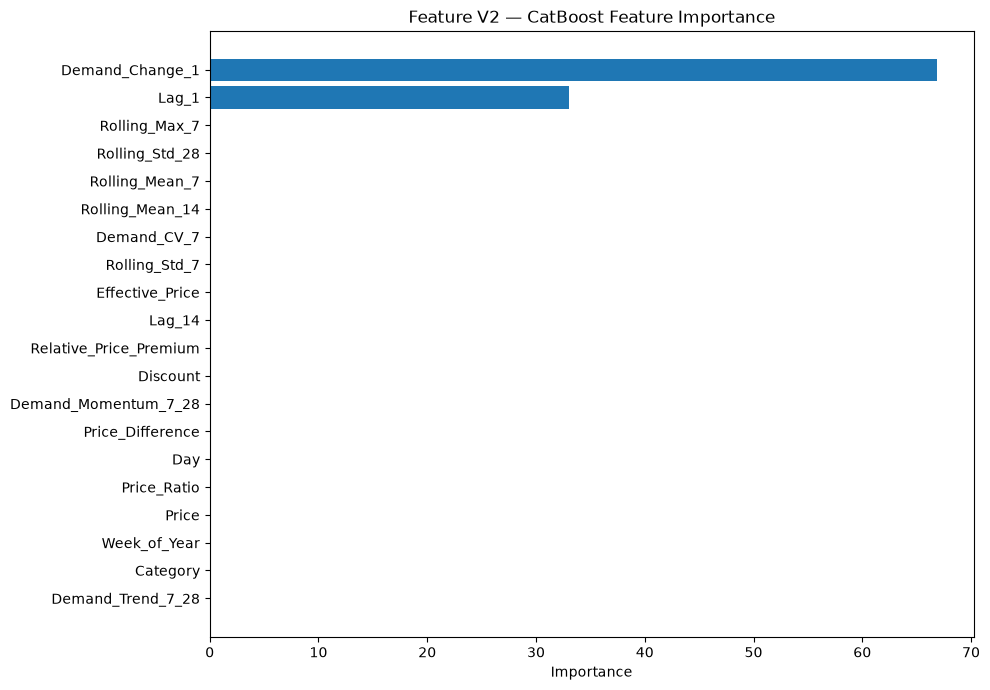

In [17]:
import matplotlib.pyplot as plt

top_features = feature_importance.head(20).sort_values("Importance")

plt.figure(figsize=(10, 7))
plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)
plt.title("Feature V2 — CatBoost Feature Importance")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

## 16. Save only if this experiment is better

Do not overwrite the current production candidate automatically. Save this as a separate experiment model.

In [18]:
models_dir = Path("../Models")
models_dir.mkdir(parents=True, exist_ok=True)

experiment_path = models_dir / "catboost_feature_v2_inventory_removed.cbm"

model.save_model(experiment_path)

joblib.dump(
    {
        "feature_columns": feature_columns,
        "categorical_features": categorical_features,
        "numerical_features": numerical_features,
        "excluded_columns": excluded_columns,
        "target_column": "Units Sold"
    },
    models_dir / "catboost_feature_v2_metadata.pkl"
)

print("Experiment model saved:")
print(experiment_path)

Experiment model saved:
..\Models\catboost_feature_v2_inventory_removed.cbm


# Decision rule

Use the comparison table to decide:

### If MAE decreases substantially
Keep Feature V2 and continue improving it.

### If MAE is similar
The inventory feature was not providing much useful information. Keep the cleaner demand-only feature set.

### If MAE gets worse
Do not automatically add inventory back. Investigate which demand features are useful using ablation/feature importance.

### Next experiment after this

If Feature V2 improves the model, we can add more advanced features such as:

- exponentially weighted demand
- same-day-of-week historical demand
- demand seasonality interactions
- price-change features
- promotion history

Then we can run Optuna again on the improved feature set.